# Лекция 6. Локальные признаки и сопоставление изображений

## План


1. **Зачем нужны локальные признаки**
2. **Детекторы особых точек**
   - Углы Харриса (Harris)
   - Shi-Tomasi (goodFeaturesToTrack)
   - FAST (Features from Accelerated Segment Test)
   - DoG (Difference of Gaussians)
3. **Дескрипторы**
   - SIFT (Scale-Invariant Feature Transform)
   - SURF (Speeded-Up Robust Features)
   - BRIEF (Binary Robust Independent Elementary Features) и ORB (Oriented FAST and Rotated BRIEF)
4. **Сопоставление дескрипторов**
   - Brute-Force, FLANN (Fast Library for Approximate Nearest Neighbors)
   - Ratio Test (Lowe)
   - Кросс-проверка
5. **RANSAC (RANdom SAmple Consensus) и гомография**
6. **Практические приложения**
   - Поиск объекта по шаблону
   - Сшивка панорам
   - Трекинг



## 1. Зачем нужны локальные признаки

### Проблема глобальных методов

Мы уже умеем:
- фильтровать изображения,
- находить контуры,
- анализировать спектр Фурье,
- искать объекты через корреляцию.

Но **корреляция Фурье** работает только при **неизменных** условиях: та же яркость, тот же масштаб, тот же ракурс. Если объект повернулся, приблизился или освещение изменилось — корреляция перестаёт работать.

Глобальные методы описывают изображение целиком.

### Идея локальных признаков

Вместо анализа изображения целиком найдём **небольшое число характерных точек**, каждая из которых:

- легко находится на обоих изображениях,
- описывается **инвариантным дескриптором** — вектором чисел, который не зависит от поворота, масштаба, яркости.


### Что такое «хорошая» особая точка

Особая точка должна быть **устойчивой** — то есть повторно находиться на другом изображении той же сцены. Такой точкой может быть:

- **угол** — пересечение двух контуров,
- **пятно** (blob) — локальный экстремум яркости,
- **край** — но край плох тем, что он «размазан» вдоль своей оси.

**Идеальный детектор** должен обладать свойствами:

| Свойство | Что означает |
|---|---|
| **Повторяемость** | Точка находится на обоих изображениях одной сцены |
| **Отличимость** | Дескриптор точки сильно отличается от дескрипторов других точек |
| **Локальность** | Точка определяется по окрестности, а не по всему изображению |
| **Инвариантность** | Устойчивость к повороту, масштабу, яркости, шуму |


## Пайплайн распознавания

1. **Детектор** -> находит особые точки (их координаты).
2. **Дескриптор** -> для каждой точки строит вектор (обычно 64–128 чисел).
3. **Матчер** -> сопоставляет дескрипторы двух изображений.
4. **Фильтрация** -> отбрасывает ложные совпадения.
5. **Геометрия** -> оценивает преобразование (гомографию, фундаментальную матрицу).

### Импорты и вспомогательные функции

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data
from skimage.feature import (
    corner_harris,
    corner_peaks,
)


def show(images, titles, figsize=(15, 5), cmap="gray"):
    """Показать несколько изображений рядом."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]
    for ax, im, title in zip(axes, images, titles):
        ax.imshow(im, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# Тестовые изображения
img_gray = data.camera()  # 512x512, grayscale
img_color = data.astronaut()  # цветное
img_checker = data.checkerboard()  # шахматная доска — идеальна для углов
print(f"camera:       {img_gray.shape}, dtype={img_gray.dtype}")
print(f"astronaut:    {img_color.shape}")
print(f"checkerboard: {img_checker.shape}")

camera:       (512, 512), dtype=uint8
astronaut:    (512, 512, 3)
checkerboard: (200, 200)


## 2. Детектор углов Харриса (Harris & Stephens, 1988)

### Идея

Сдвинем небольшое окно $W$ вокруг точки $(x, y)$ на вектор $(\Delta x, \Delta y)$. Если содержимое окна сильно изменилось — значит, здесь «что-то есть». Формально:

$$E(\Delta x, \Delta y) = \sum_{(x,y) \in W} w(x,y) \left[ I(x+\Delta x, y+\Delta y) - I(x, y) \right]^2$$

где $w(x,y)$ — весовая функция (обычно гауссиана).



### Приближение Тейлора

Разложим $I(x+\Delta x, y+\Delta y)$ в ряд Тейлора:

$$I(x+\Delta x, y+\Delta y) \approx I(x, y) + I_x \Delta x + I_y \Delta y$$

Тогда:

$$E(\Delta x, \Delta y) \approx \sum_{W} w \left[ I_x \Delta x + I_y \Delta y \right]^2 = \begin{bmatrix} \Delta x & \Delta y \end{bmatrix} M \begin{bmatrix} \Delta x \\ \Delta y \end{bmatrix}$$

где **матрица структуры** $M$:

$$M = \sum_{W} w \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix}$$

### Собственные числа $M$

Пусть $\lambda_1, \lambda_2$ — собственные числа $M$. Их значения показывают, насколько сильно меняется яркость по двум главным направлениям:

| Случай | $\lambda_1$ | $\lambda_2$ | Интерпретация |
|---|---|---|---|
| Плоская область | малые | малые | ничего интересного |
| Вертикальный край | большая | малая | меняется только по одному направлению |
| Горизонтальный край | малая | большая | тоже край |
| **Угол** | **большая** | **большая** | меняется по обоим направлениям |

### Отклик Харриса

Вместо явного вычисления собственных чисел используют функцию отклика:

$$R = \det(M) - k \cdot \operatorname{trace}(M)^2 = \lambda_1 \lambda_2 - k(\lambda_1 + \lambda_2)^2$$

где $k \approx 0.04\dots0.06$ — эмпирическая константа.

**Правило:**
- $R \gg 0$ -> угол
- $R \ll 0$ -> край
- $|R|$ мало -> плоская область

### Углы Харриса в scikit-image

Найдено углов: 49


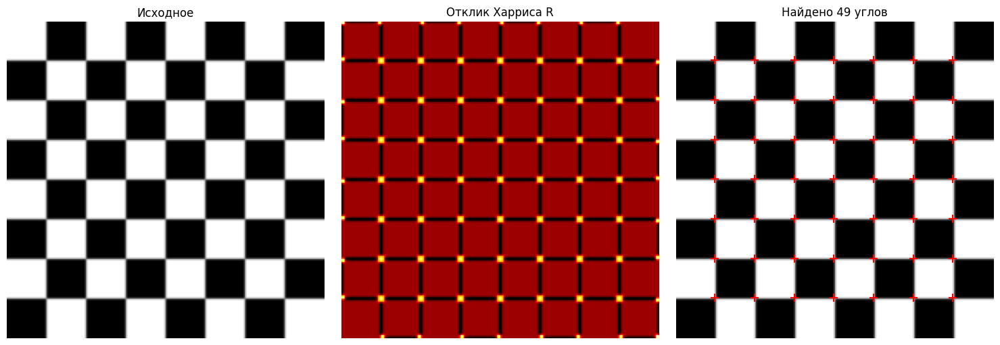

In [ ]:
img = data.checkerboard()

# Карта отклика Харриса
harris_response = corner_harris(img)

# Извлекаем пики — сами углы
coords = corner_peaks(harris_response, min_distance=5, threshold_rel=0.1)
print(f"Найдено углов: {len(coords)}")

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное")
axes[0].axis("off")
axes[1].imshow(harris_response, cmap="hot")
axes[1].set_title("Отклик Харриса R")
axes[1].axis("off")
axes[2].imshow(img, cmap="gray")
axes[2].plot(coords[:, 1], coords[:, 0], "r+", markersize=8, markeredgewidth=1.5)
axes[2].set_title(f"Найдено {len(coords)} углов")
axes[2].axis("off")
plt.tight_layout()
plt.show()

**Интерпретация**

- На карте отклика яркие точки соответствуют высокому $R$ и локализованы **в узлах пересечения клеток шахматной доски**.
- Вдоль границ клеток отклик близок к нулю или отрицателен — это правило $R \ll 0 \Rightarrow$ край.
- Найдено 49 углов — примерно равно числу вершин клеток.


- `min_distance=5` подавляет дубли, `threshold_rel=0.1` отсекает слабые пики.


### Дополнительно: как отклик Харриса «видит» разные типы областей

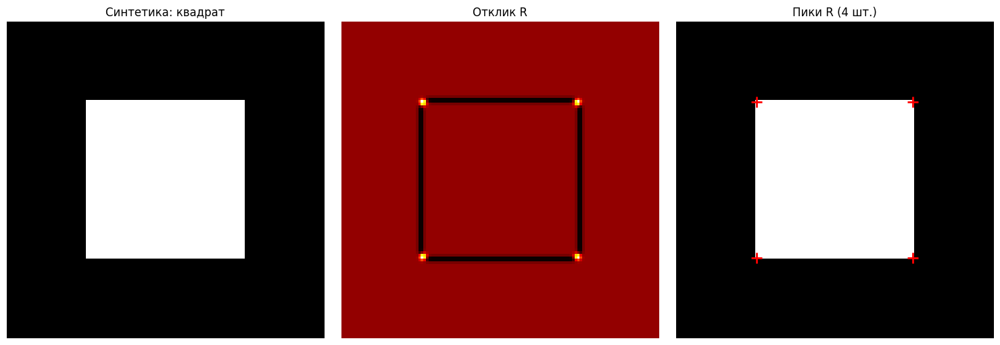

In [ ]:
synthetic = np.zeros((120, 120), dtype=np.float32)
synthetic[30:90, 30:90] = 1.0
resp = corner_harris(synthetic)
peaks = corner_peaks(resp, min_distance=5, threshold_rel=0.1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(synthetic, cmap="gray")
axes[0].set_title("Синтетика: квадрат")
axes[0].axis("off")
axes[1].imshow(resp, cmap="hot")
axes[1].set_title("Отклик R")
axes[1].axis("off")
axes[2].imshow(synthetic, cmap="gray")
axes[2].plot(peaks[:, 1], peaks[:, 0], "r+", markersize=12, markeredgewidth=2)
axes[2].set_title(f"Пики R ({len(peaks)} шт.)")
axes[2].axis("off")
plt.tight_layout()
plt.show()


**Интерпретация.**

- Максимум отклика — в четырёх вершинах квадрата; их и находит `corner_peaks`.
- Вдоль сторон $R$ мало или отрицательно — детектор считает их краями.
- Внутри и снаружи квадрата отклик почти нулевой — плоская область.


### Углы Харриса в OpenCV

В OpenCV есть готовая функция `cv2.cornerHarris`, возвращающая карту отклика:

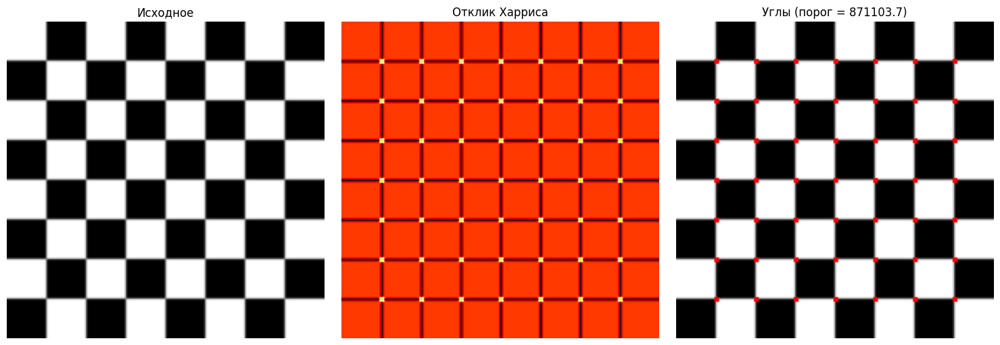

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

img = data.checkerboard().astype(np.float32)
harris = cv2.cornerHarris(img, blockSize=2, ksize=3, k=0.04)
harris_norm = cv2.normalize(harris, None, 0, 255, cv2.NORM_MINMAX)  # <- исправлено
threshold = 0.01 * harris.max()
corner_mask = harris > threshold

vis = cv2.cvtColor((img * 255 / img.max()).astype(np.uint8), cv2.COLOR_GRAY2RGB)
vis[corner_mask] = [255, 0, 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное")
axes[0].axis("off")
axes[1].imshow(harris_norm, cmap="hot")
axes[1].set_title("Отклик Харриса")
axes[1].axis("off")
axes[2].imshow(vis)
axes[2].set_title(f"Углы (порог = {threshold:.1f})")
axes[2].axis("off")
plt.tight_layout()
plt.show()

**Интерпретация.**

- `cv2.cornerHarris` возвращает **сырой отклик** $R$, а не список углов. Маска строится вручную.
- Красным подсвечены все пиксели с откликом выше порога — вокруг истинных углов образуются «толстые» пятна, потому что нет non-maximum suppression.
- В scikit-image `corner_peaks` сам подавляет немаксимумы, поэтому там углы «тонкие».


### Дополнительно: как параметр $k$ меняет отклик Харриса

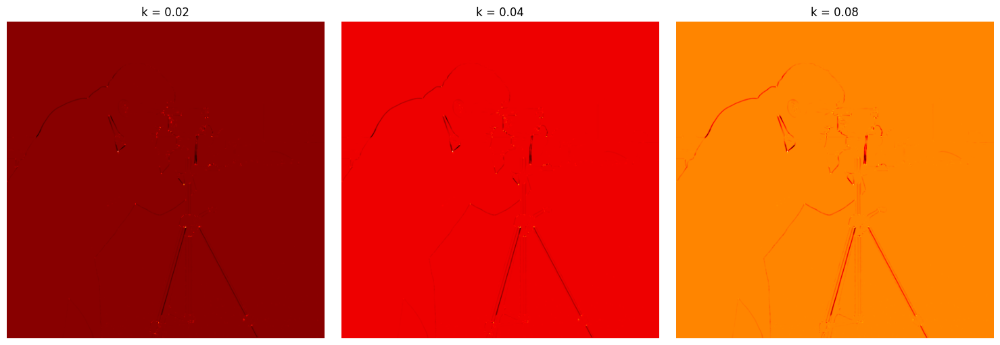

Число пикселей с R > 0.01*max при разных k:
  k=0.02: 1336
  k=0.04: 1010
  k=0.08: 628


In [ ]:
img = data.camera().astype(np.float32)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, k_val in zip(axes, [0.02, 0.04, 0.08]):
    R = cv2.cornerHarris(img, blockSize=2, ksize=3, k=k_val)
    ax.imshow(R, cmap="hot")
    ax.set_title(f"k = {k_val}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Число пикселей с R > 0.01*max при разных k:")
for k_val in [0.02, 0.04, 0.08]:
    R = cv2.cornerHarris(img, blockSize=2, ksize=3, k=k_val)
    print(f"  k={k_val}: {(R > 0.01 * R.max()).sum()}")


**Интерпретация.**

- С ростом $k$ ослабляются отклики на краях.
- Число пикселей выше порога **уменьшается**: детектор оставляет только наиболее «угловые» точки.
- Оптимум: $k \in [0.04, 0.06]$.


## 3. Детектор Shi-Tomasi (goodFeaturesToTrack, 1994)


### Проблема детектора Харриса

Функция отклика $R = \lambda_1 \lambda_2 - k(\lambda_1 + \lambda_2)^2$ зависит от эмпирической константы $k$. Разные $k$ дают разные результаты.


### Идея Shi-Tomasi

Заменим отклик на **минимум из двух собственных чисел**:

$$R = \min(\lambda_1, \lambda_2)$$

**Геометрический смысл:** если обе кривизны велики, то и минимум велик. Точки, где это верно — устойчивые углы, которые хорошо отслеживать между кадрами. Отсюда название метода — *good features to track* (хорошие признаки для трекинга).

### Преимущества


- Нет эмпирического параметра $k$.
- Лучше подходит для трекинга (например, в оптическом потоке Lucas-Kanade).



### В Shi-Tomasi в OpenCV


Найдено углов: 100


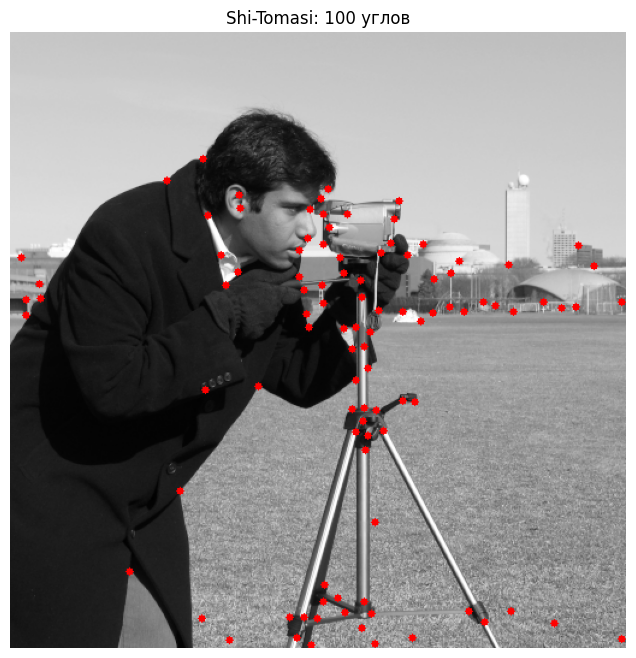

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

# Берём изображение с шахматной доской и фотореалистичное
img = data.camera().astype(np.uint8)  # grayscale 512x512
gray = img.copy()

corners = cv2.goodFeaturesToTrack(
    gray,
    maxCorners=100,  # сколько углов максимум вернуть
    qualityLevel=0.01,  # порог качества (доля от лучшего отклика)
    minDistance=10,  # минимальное расстояние между углами
    blockSize=3,
    useHarrisDetector=False,  # False = Shi-Tomasi, True = Harris
)

print(f"Найдено углов: {len(corners)}")

vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
for c in corners:
    x, y = c.ravel()
    cv2.circle(vis, (int(x), int(y)), 3, (255, 0, 0), -1)

plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.title(f"Shi-Tomasi: {len(corners)} углов")
plt.axis("off")
plt.show()

**Интерпретация.**

- Точки сконцентрированы в текстурированных областях, почти нет в гладком фоне.
- Такие точки оптимальны для optical flow.


### Дополнительно: Shi-Tomasi vs Harris на одном изображении

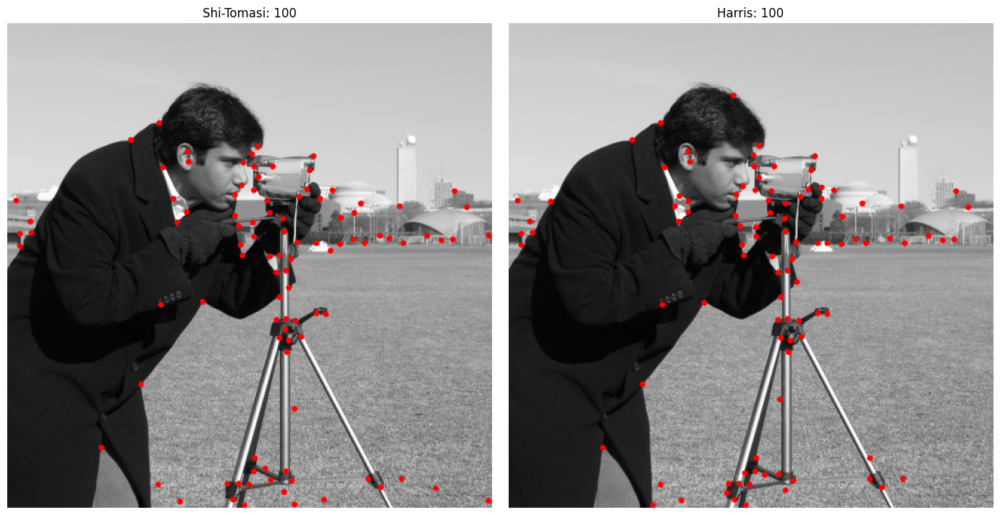

In [ ]:
gray = data.camera().astype(np.uint8)
corners_st = cv2.goodFeaturesToTrack(
    gray, 100, 0.01, 10, blockSize=3, useHarrisDetector=False
)
corners_h = cv2.goodFeaturesToTrack(
    gray, 100, 0.01, 10, blockSize=3, useHarrisDetector=True
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, pts, title in [
    (axes[0], corners_st, f"Shi-Tomasi: {len(corners_st)}"),
    (axes[1], corners_h, f"Harris: {len(corners_h)}"),
]:
    im = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    for c in pts:
        x, y = c.ravel()
        cv2.circle(im, (int(x), int(y)), 3, (255, 0, 0), -1)
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Интерпретация.**

- Наборы точек похожи, но не идентичны.
- Shi-Tomasi стабильнее: нет параметра $k$.
- Поэтому `goodFeaturesToTrack` по умолчанию использует Shi-Tomasi.


## 4. Детектор FAST (Features from Accelerated Segment Test)



### Идея



FAST работает с **кругом (окрестностью) из 16 пикселей** вокруг рассматриваемой точки. Точка считается углом, если существует дуга из $N$ **подряд идущих** пикселей на этом круге, яркость которых отличается от яркости центра на порог $t$.


### Условие FAST-9

Для точки $p$ с яркостью $I_p$ и порога $t$:

1. Пиксель $x$ на круге считается **ярким**, если $I_x > I_p + t$.
2. Пиксель $x$ считается **тёмным**, если $I_x < I_p - t$.
3. Точка $p$ — угол, если на круге есть дуга минимум из **9** (или 10, 11, 12) подряд идущих ярких или тёмных пикселей.


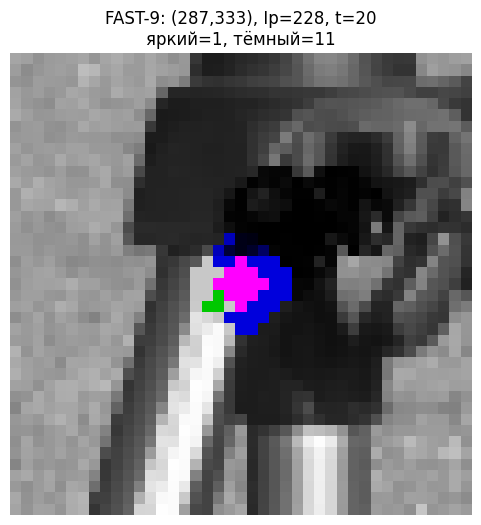

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

img = data.camera().astype(np.uint8)
C = [
    (0, -3),
    (1, -3),
    (2, -2),
    (3, -1),
    (3, 0),
    (3, 1),
    (2, 2),
    (1, 3),
    (0, 3),
    (-1, 3),
    (-2, 2),
    (-3, 1),
    (-3, 0),
    (-3, -1),
    (-2, -2),
    (-1, -3),
]
t = 20
kp = min(
    cv2.FastFeatureDetector_create(t, True).detect(img, None), key=lambda k: -k.response
)
x, y = map(int, kp.pt)
Ip = int(img[y, x])
v = np.array([int(img[y + dy, x + dx]) for dy, dx in C])
lab = np.where(v > Ip + t, 1, np.where(v < Ip - t, -1, 0))

crop = cv2.cvtColor(img[y - 20 : y + 21, x - 20 : x + 21], cv2.COLOR_GRAY2RGB)
col = {1: (0, 200, 0), -1: (0, 0, 220), 0: (200, 200, 200)}
for i, (dy, dx) in enumerate(C):
    cv2.circle(crop, (20 + dx, 20 + dy), 1, col[lab[i]], -1)
    cv2.putText(crop, str(i + 1), (21 + dx, 19 + dy), 0, 0.3, (0, 0, 0), 1, cv2.LINE_AA)
cv2.circle(crop, (20, 20), 2, (255, 0, 255), -1)

plt.figure(figsize=(6, 6))
plt.imshow(crop)
plt.axis("off")
plt.title(
    f"FAST-9: ({x},{y}), Ip={Ip}, t={t}\nяркий={(lab == 1).sum()}, тёмный={(lab == -1).sum()}"
)
plt.show()

## Что показывает визуализация

- **Малиновый центр** — пиксель $p$ (координаты `(287, 333)`), его яркость $I_p = 228$ (очень светлый, почти белый).
- **Синие точки** — 11 пикселей круга, у которых $I_x < I_p - t$, то есть **тёмные**.
- **Зелёная точка** — единственный **яркий** пиксель ($> I_p + t$), попал на светлый участок.
- **Серых нет** — либо пиксель яркий, либо тёмный; все значения попали за «мёртвую зону» $|I_x - I_p| \le t$.




### Ускорение

1. Сначала проверяются только 4 пикселя на «кресте»: 1, 5, 9, 13.
2. Если минимум 3 из них не удовлетворяют условию — точка отбрасывается сразу (это отсеивает ~90% точек).
3. Только для оставшихся проверяются все 16 пикселей.



### Плюсы и минусы



| Плюсы | Минусы |
|---|---|
| Очень быстрый | Не инвариантен к масштабу |
| Хорошо работает в реальном времени | Чувствителен к шуму |
| Много точек | Нет ориентации |

Обычно FAST используется как **детектор** для ORB (Oriented FAST and Rotated BRIEF).

### FAST в OpenCV

FAST: найдено 1247 ключевых точек


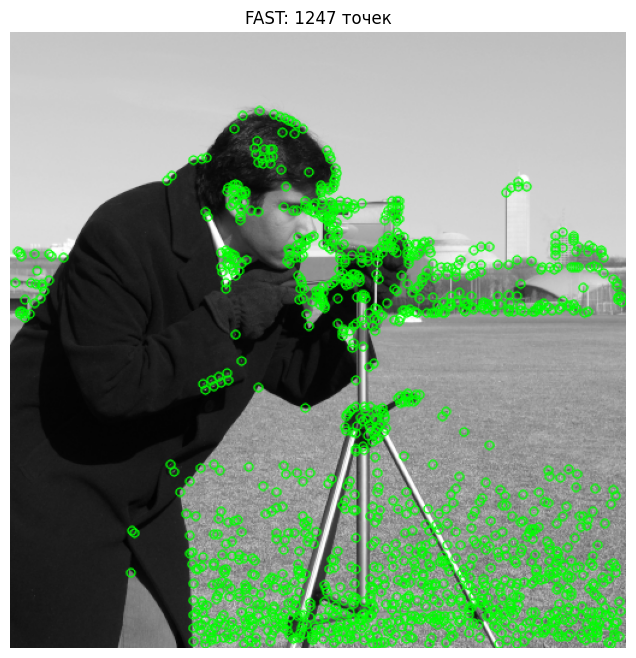

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

img = data.camera().astype(np.uint8)

fast = cv2.FastFeatureDetector_create(
    threshold=30,  # порог яркости t
    nonmaxSuppression=True,
    type=cv2.FAST_FEATURE_DETECTOR_TYPE_9_16,
)

kp = fast.detect(img, None)
print(f"FAST: найдено {len(kp)} ключевых точек")

vis = cv2.drawKeypoints(
    img, kp, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.title(f"FAST: {len(kp)} точек")
plt.axis("off")
plt.show()

**Интерпретация.**

- Найдено 1247 точек — на порядок больше, чем Shi-Tomasi при `maxCorners=100`.
- FAST чувствителен к локальному контрасту, а не к форме угла; точки покрывают всё изображение.
- `FAST_FEATURE_DETECTOR_TYPE_9_16` — классическое условие FAST-9.
- Для сопоставления «сам по себе» не годится: нет дескриптора и ориентации.

### Дополнительно: влияние порога `threshold` на FAST

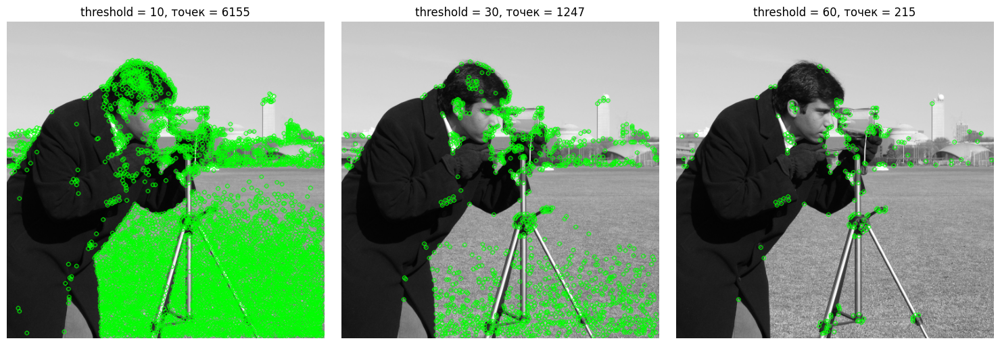

In [ ]:
img = data.camera().astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, thr in zip(axes, [10, 30, 60]):
    f = cv2.FastFeatureDetector_create(
        threshold=thr, nonmaxSuppression=True, type=cv2.FAST_FEATURE_DETECTOR_TYPE_9_16
    )
    kps = f.detect(img, None)
    vis = cv2.drawKeypoints(img, kps, None, color=(0, 255, 0))
    ax.imshow(vis)
    ax.set_title(f"threshold = {thr}, точек = {len(kps)}")
    ax.axis("off")
plt.tight_layout()
plt.show()


**Интерпретация.**

- При `threshold=10` — тысячи точек, включая шумовые.
- При `threshold=60` — только самые контрастные углы.
- Компромисс: низкий порог -> больше точек и выше повторяемость, но много мусора; высокий -> чище, но можно потерять полезные.
- Для ORB-дескриптора обычно `threshold ≈ 20–30`.


## 5. Детектор DoG (Difference of Gaussians)

### Идея

**LoG** (Laplacian of Gaussian) — это вторая производная гауссианы, применённая к изображению; его отклик резко максимален в центре «пятна» (blob) и потому идеален для детекции пятен на фиксированном масштабе $\sigma$. **DoG** (Difference of Gaussians) — это разность двух гауссиан с $\sigma$ и $k\sigma$, и она **аппроксимирует LoG** с точностью до константы: $\frac{\partial G}{\partial \sigma} = \sigma \nabla^2 G$, поэтому $G(k\sigma) - G(\sigma) \approx (k-1)\sigma \cdot \text{LoG}_\sigma$. На практике DoG дешевле (два размытия и вычитание) и используется в SIFT как замена LoG; при $k \approx 1.6$ кривые почти совпадают.


### Формула

$$D(x, y, \sigma) = \left( G(x, y, k\sigma) - G(x, y, \sigma) \right) * I(x, y)$$

где $G$ — гауссиана с параметром $\sigma$.

### Масштабная пирамида

1. Строим **пирамиду гауссиан** с разными $\sigma$ (обычно $\sigma$, $k\sigma$, $k^2\sigma$, …).
2. Вычисляем DoG-разности между соседними уровнями.
3. Ищем **локальные экстремумы** в 3D-пространстве $(x, y, \sigma)$ — пиксель сравнивается с 26 соседями (8 в своём масштабе и по 9 в соседних).



### Роль

DoG — **основа SIFT**: именно он находит ключевые точки на разных масштабах, что делает SIFT инвариантным к масштабу.

### DoG в scikit-image: blobs_log / blobs_dog

DoG: найдено 154 пятен
LoG: найдено 240 пятен


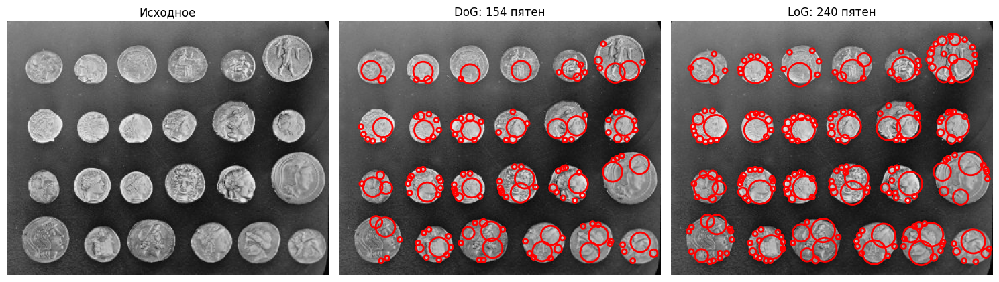

In [ ]:
import matplotlib.pyplot as plt
from skimage import data
from skimage.feature import blob_dog, blob_log

img = data.coins().astype(float) / 255.0

# DoG-детекция пятен
blobs_dog_ = blob_dog(img, min_sigma=2, max_sigma=10, sigma_ratio=1.6, threshold=0.1)
blobs_log_ = blob_log(img, min_sigma=2, max_sigma=10, num_sigma=10, threshold=0.1)

print(f"DoG: найдено {len(blobs_dog_)} пятен")
print(f"LoG: найдено {len(blobs_log_)} пятен")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное")
axes[0].axis("off")

for ax, blobs, title in [(axes[1], blobs_dog_, "DoG"), (axes[2], blobs_log_, "LoG")]:
    ax.imshow(img, cmap="gray")
    for y, x, r in blobs:
        circle = plt.Circle((x, y), r * 1.41, color="red", fill=False, linewidth=2)
        ax.add_patch(circle)
    ax.set_title(f"{title}: {len(blobs)} пятен")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Интерпретация.**

- DoG/LoG ищут не «точки», а **пятна** — круглые области с локальным экстремумом яркости.
- DoG находит меньше пятен, чем LoG (154 vs 240): DoG — приближение LoG и работает грубее, зато быстрее.
- Радиус пятна ≈ $\sigma\sqrt{2}$ (в коде `r * 1.41`).
- `min_sigma=2, max_sigma=10` ограничивают диапазон масштабов.
- На фото `coins` точки хорошо садятся на центры монет.


### Дополнительно: гауссова пирамида и DoG-разности

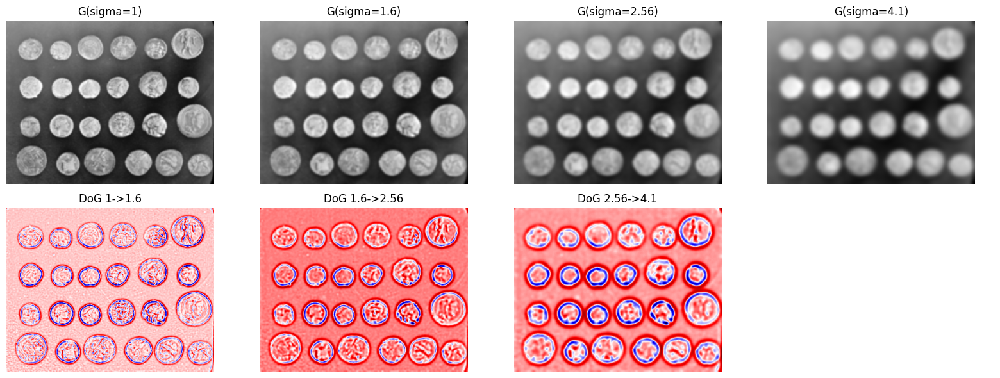

In [ ]:
from scipy.ndimage import gaussian_filter

img = data.coins().astype(float) / 255.0
sigmas = [1, 1.6, 2.56, 4.1]
gaussians = [gaussian_filter(img, s) for s in sigmas]

fig, axes = plt.subplots(2, len(sigmas), figsize=(16, 6))
for i, (g, s) in enumerate(zip(gaussians, sigmas)):
    axes[0, i].imshow(g, cmap="gray")
    axes[0, i].set_title(f"G(sigma={s})")
    axes[0, i].axis("off")

for i in range(len(sigmas) - 1):
    dog = gaussians[i + 1] - gaussians[i]
    axes[1, i].imshow(dog, cmap="seismic")
    axes[1, i].set_title(f"DoG {sigmas[i]}->{sigmas[i + 1]}")
    axes[1, i].axis("off")
axes[1, -1].axis("off")
plt.tight_layout()
plt.show()


**Интерпретация.**

- Верхний ряд — гауссианы с возрастающим $\sigma$: изображение всё более размытое, мелкие детали исчезают, остаются крупные структуры.
- Нижний ряд — попиксельные разности: красные области — там, где более широкий гаусс даёт бо́льшую яркость (тёмные пятна на светлом), синие — наоборот.
- Именно эти разности используются в SIFT: точки с локальным экстремумом по $(x, y, \sigma)$ — кандидаты в ключевые, а масштаб $\sigma$ даёт инвариантность к размеру.
- Нас интересуют **экстремумы в 3D** $(x, y, \sigma)$, а не сами значения DoG.


## 6. Дескрипторы

### SIFT (Scale-Invariant Feature Transform, Lowe, 2004)

SIFT объединяет **детектор** (DoG в масштабной пирамиде) и **дескриптор** — вектор из 128 чисел, описывающий распределение градиентов вокруг ключевой точки.

Свойства дескриптора:
- **Инвариантность к масштабу** достигается за счёт выбора ключевых точек на разных уровнях гауссовой пирамиды.
- **Инвариантность к повороту** — за счёт оценки доминирующей ориентации градиентов и поворота окрестности.
- **Инвариантность к яркости** — за счёт нормализации гистограмм.

Окрестность $16\times16$ разбивается на $4\times4$ блока по $4\times4$ пикселя; в каждом блоке считается 8-бинная гистограмма направлений градиента. Итог: $4\cdot4\cdot8 = 128$ чисел.


SIFT: точек = 791, размер дескриптора = (791, 128)


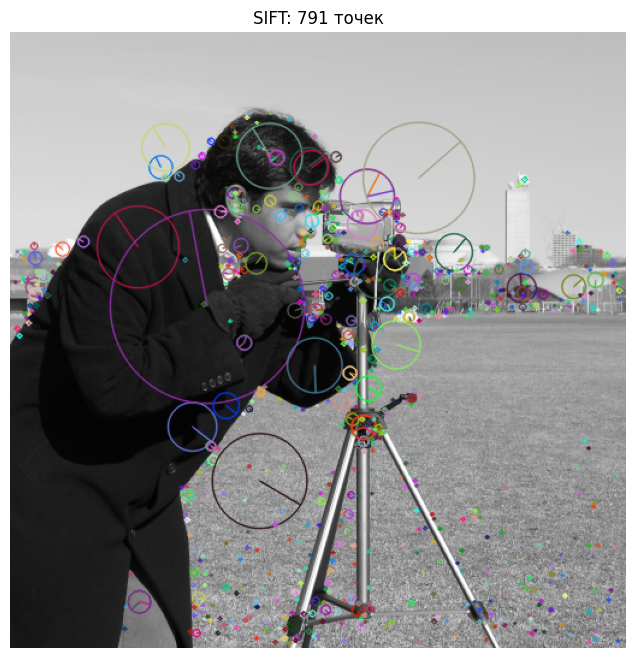

In [ ]:
sift = cv2.SIFT_create()
kp_sift, des_sift = sift.detectAndCompute(img_gray, None)
print(f"SIFT: точек = {len(kp_sift)}, размер дескриптора = {des_sift.shape}")

vis_sift = cv2.drawKeypoints(
    img_gray, kp_sift, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(8, 8))
plt.imshow(vis_sift)
plt.title(f"SIFT: {len(kp_sift)} точек")
plt.axis("off")
plt.show()


**Интерпретация.**

- `detectAndCompute` возвращает сразу и ключевые точки, и дескрипторы. В нашем случае: около тысячи точек и матрица `N × 128`.
- Размер круга на визуализации пропорционален **масштабу** $\sigma$, найденному в пирамиде DoG: большие круги — крупные структуры, маленькие — мелкие детали.
- Радиальная черта внутри круга — **ориентация**, которую SIFT оценивает по доминирующему направлению градиентов. Именно она обеспечивает инвариантность к повороту.
- SIFT — эталон качества, но **медленный** и защищён патентом (в OpenCV вынесен в отдельный модуль `xfeatures2d`, но в новых версиях перенесён обратно в `cv2`).


### ORB (Oriented FAST and Rotated BRIEF)

ORB — это «быстрая и бесплатная» альтернатива SIFT/SURF:

- **Детектор** — FAST с ориентацией (oFAST): для каждой точки вычисляется угол по центру масс яркости в окрестности.
- **Дескриптор** — модифицированный BRIEF (**rBRIEF**): бинарный вектор, где каждый бит — результат сравнения пары пикселей в повёрнутой системе координат.
- Итоговый дескриптор — 256 бит (32 байта). Сравнение — по расстоянию Хэмминга.


ORB: точек = 500, размер дескриптора = (500, 32), dtype = uint8


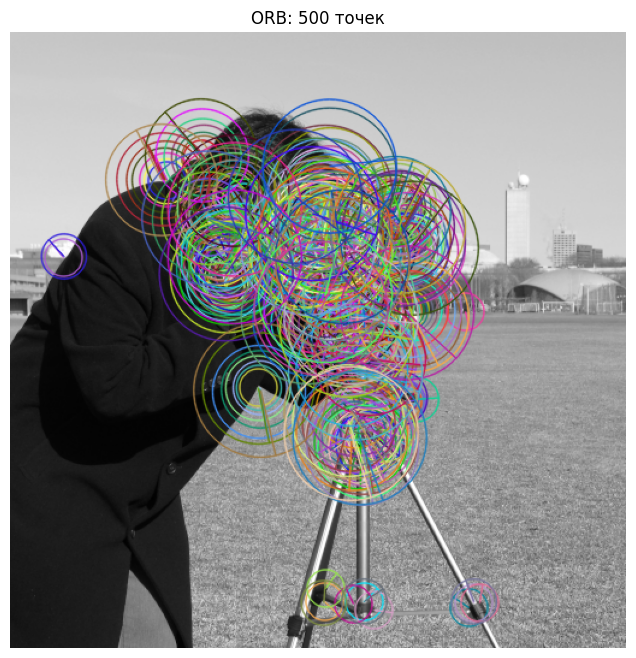

In [ ]:
orb = cv2.ORB_create(nfeatures=500)
kp_orb, des_orb = orb.detectAndCompute(img_gray, None)
print(
    f"ORB: точек = {len(kp_orb)}, размер дескриптора = {des_orb.shape}, dtype = {des_orb.dtype}"
)

vis_orb = cv2.drawKeypoints(
    img_gray, kp_orb, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(8, 8))
plt.imshow(vis_orb)
plt.title(f"ORB: {len(kp_orb)} точек")
plt.axis("off")
plt.show()


**Интерпретация.**

- `nfeatures=500` — верхняя граница; ORB сам выбирает сильнейшие 500 ключевых точек по отклику FAST.
- Дескриптор имеет shape `(N, 32)` и dtype `uint8` — это 256 бит в 32 байтах, что в 4 раза меньше SIFT (128 float = 512 байт). Отсюда большая скорость.
- Сравнение дескрипторов делается через **расстояние Хэмминга** (`cv2.NORM_HAMMING`), а не L2. Это работает в разы быстрее.
- На визуализации видно, что ORB находит гораздо больше точек в текстурированных областях, чем в гладких, — FAST чувствителен к локальному контрасту.


### SURF — короткая справка

SURF (Bay et al., 2006) — ускоренная версия SIFT: вместо DoG использует box-фильтры (аппроксимация второй производной гауссианы), а дескриптор — 64 числа вместо 128.

- **Плюс:** в 3–5 раз быстрее SIFT.
- **Минус:** защищён патентом (использовать можно только для некоммерческих задач), поэтому в стандартной `opencv-python` его нет.
- В новых версиях OpenCV SURF доступен через `cv2.xfeatures2d.SURF_create()`, если установлен `opencv-contrib-python`.

Для учебных целей достаточно знать, что SURF — это «быстрый SIFT с box-аппроксимацией»; в современном коде чаще выбирают между SIFT и ORB.


## 7. Сопоставление дескрипторов

### Brute-Force Matcher

Brute-Force (BF) сравнивает каждый дескриптор первого изображения с каждым дескриптором второго. Для SIFT используется норма L2, для ORB — расстояние Хэмминга.

Простой BF-матчинг почти всегда содержит много ложных пар — поэтому следующим шагом нужен **Ratio Test (Lowe)**.


BF: 1105 пар, лучший distance = 7.14, худший = 463.51


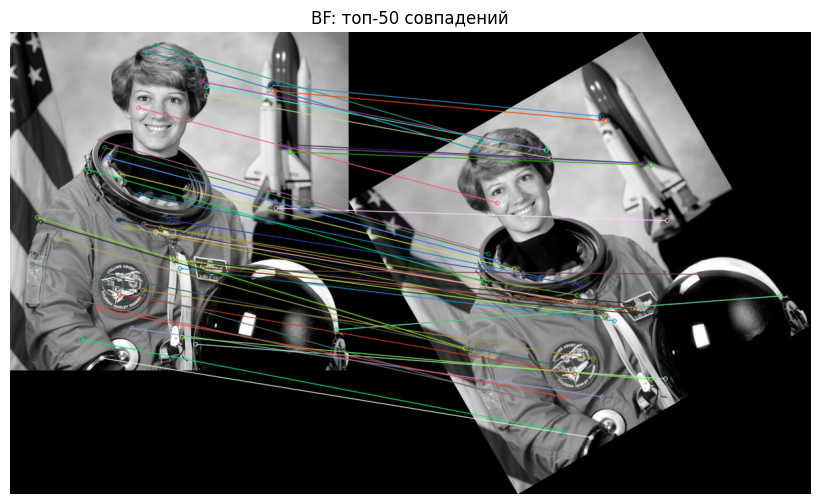

In [ ]:
# Имитируем «другое изображение»: повернём и сдвинем астронавта
from skimage.transform import rotate

img1 = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)
img2 = rotate(img1, 30, resize=True)
img2 = (img2 * 255).astype(np.uint8)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda m: m.distance)
print(
    f"BF: {len(matches)} пар, лучший distance = {matches[0].distance:.2f}, худший = {matches[-1].distance:.2f}"
)

img_matches = cv2.drawMatches(img1, kp1, img2, kp2, matches[:50], None, flags=2)
plt.figure(figsize=(14, 6))
plt.imshow(img_matches)
plt.title("BF: топ-50 совпадений")
plt.axis("off")
plt.show()


**Интерпретация.**

- `bf.match` возвращает пары **по одной на каждый дескриптор** — это «лучший вариант» без учёта надёжности.
- Распределение `distance` очень неоднородно: лучший ≈ 0 (это по сути точные совпадения на повёрнутом изображении), худший — сотни. Сортировка по расстоянию помогает визуально оставить только «уверенные» пары.
- Топ-50 пар на картинке выглядят правдоподобно, но среди **всех** пар есть и ошибочные — именно поэтому нужен Ratio Test.


### Ratio Test (Lowe)

Для каждого дескриптора ищем **два** ближайших: $d_1$ (лучший) и $d_2$ (второй). Пара принимается, только если:

$$d_1 / d_2 < \rho, \quad \rho \approx 0.7\!-\!0.8$$

Идея: у правильного совпадения второй кандидат заметно хуже. Если оба похожи — точка «неуникальна», и её лучше отбросить.


После Ratio Test (ρ=0.75): 713 пар


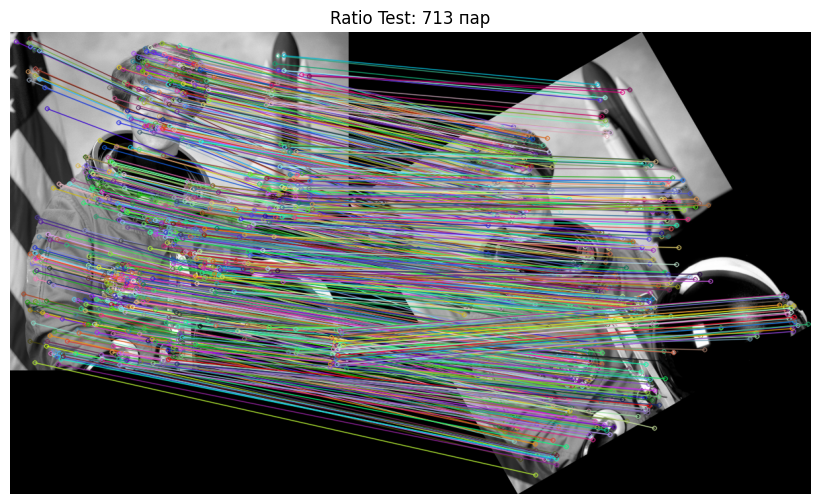

In [ ]:
bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des1, des2, k=2)

good = []
for m, n in knn:
    if m.distance < 0.75 * n.distance:
        good.append(m)

print(f"После Ratio Test (ρ=0.75): {len(good)} пар")

img_good = cv2.drawMatches(img1, kp1, img2, kp2, good, None, flags=2)
plt.figure(figsize=(14, 6))
plt.imshow(img_good)
plt.title(f"Ratio Test: {len(good)} пар")
plt.axis("off")
plt.show()


**Интерпретация.**

- Порог $\rho=0.75$ — стандартный компромисс: при $\rho \to 1$ пропускаем почти всё, при $\rho \to 0.5$ остаются только очень уверенные пары.
- На повёрнутом изображении SIFT даёт десятки очень надёжных пар: видно, что линии соединяют соответствующие области (глаз, шлем, фон).
- Если бы мы взяли ORB, картина была бы похожей, но с большим числом пар (ORB-дескриптор «шумнее»); там Ratio Test особенно важен.


### FLANN (Fast Library for Approximate Nearest Neighbors)

FLANN — **приближённый** поиск ближайших соседей. Для SIFT обычно используют `KDTreeIndex`, для бинарных дескрипторов (ORB) — `LSH`.

Ускорение достигается за счёт того, что FLANN не гарантирует **точный** ближайший сосед, но ошибается редко. На больших изображениях это даёт выигрыш в десятки раз.


FLANN + Ratio Test: 715 пар


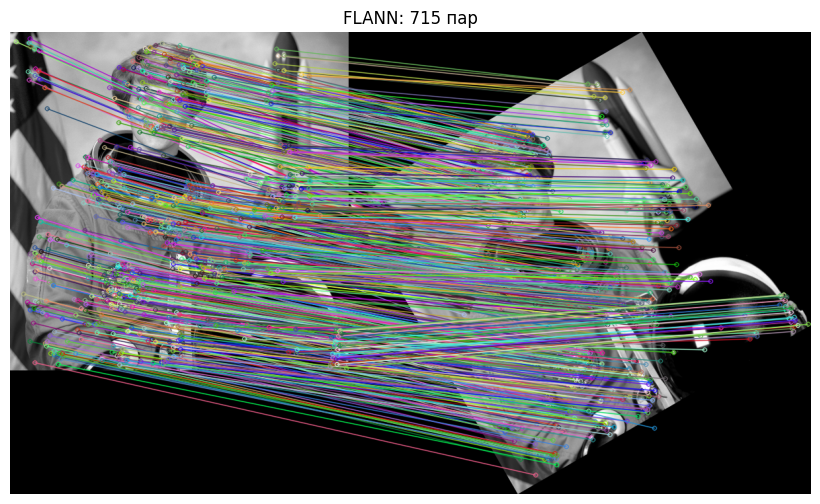

In [ ]:
FLANN_INDEx_KDTREE = 1
index_params = {"algorithm": FLANN_INDEx_KDTREE, "trees": 5}
search_params = {"checks": 50}

flann = cv2.FlannBasedMatcher(index_params, search_params)
knn_flann = flann.knnMatch(des1, des2, k=2)

good_flann = [m for m, n in knn_flann if m.distance < 0.75 * n.distance]
print(f"FLANN + Ratio Test: {len(good_flann)} пар")

img_flann = cv2.drawMatches(img1, kp1, img2, kp2, good_flann, None, flags=2)
plt.figure(figsize=(14, 6))
plt.imshow(img_flann)
plt.title(f"FLANN: {len(good_flann)} пар")
plt.axis("off")
plt.show()


**Интерпретация.**

- Результат визуально практически не отличается от BF+Ratio: FLANN нашёл те же пары, просто быстрее.
- На маленьких изображениях разница по времени незаметна; на больших (тысячи дескрипторов) FLANN обычно в 5–20 раз быстрее BF.
- Для ORB `algorithm` надо заменить на `FLANN_INDEx_LSH`, а норму — на `cv2.NORM_HAMMING`.


### Кросс-проверка (Cross Check)

Ещё один способ отсеять ложные пары: пара $(i, j)$ считается надёжной, только если **лучший сосед $i$ во втором изображении — это $j$**, и наоборот. В OpenCV включается опцией `crossCheck=True` в `BFMatcher`.

Часто комбинируют Ratio Test + Cross Check — это даёт максимально «чистый» набор пар.


Cross Check: 765 пар


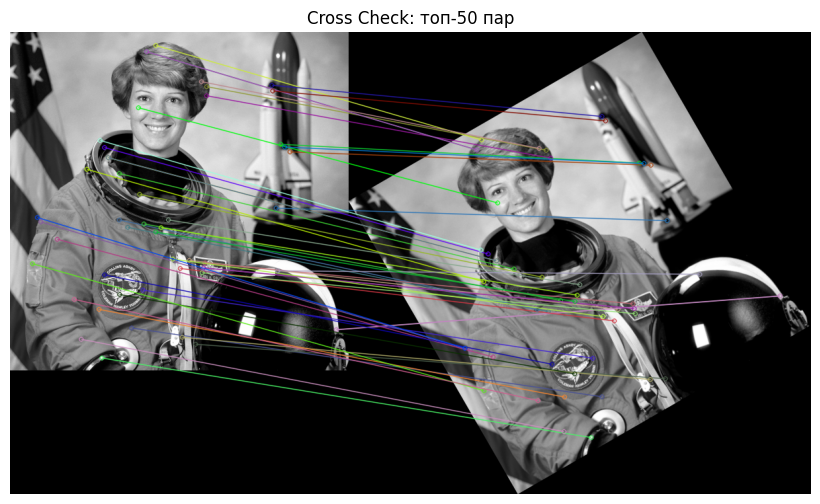

In [ ]:
bf_cc = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
matches_cc = sorted(bf_cc.match(des1, des2), key=lambda m: m.distance)
print(f"Cross Check: {len(matches_cc)} пар")

img_cc = cv2.drawMatches(img1, kp1, img2, kp2, matches_cc[:50], None, flags=2)
plt.figure(figsize=(14, 6))
plt.imshow(img_cc)
plt.title("Cross Check: топ-50 пар")
plt.axis("off")
plt.show()


**Интерпретация.**

- Cross Check оставляет только **взаимно лучшие** пары, поэтому их меньше, но они чище.
- В отличие от Ratio Test, кросс-проверка не требует параметра $\rho$ — она «беспараметрическая», но менее гибкая.
- Обычно после Cross Check число пар уменьшается в 2–5 раз по сравнению с наивным BF, зато почти все они «правильные».


## 8. RANSAC и гомография

Даже после Ratio Test остаются ошибочные пары. RANSAC (**RAN**dom **SA**mple **C**onsensus) находит модель преобразования, **согласованную с большинством** пар:

1. Случайно выбираем минимальный набор пар (для гомографии — 4).
2. Строим по ним матрицу $H$ (3×3).
3. Считаем, сколько пар согласуются с $H$ в пределах порога `ransacReprojThreshold`.
4. Повторяем, пока не найдём $H$ с максимумом inliers.

Гомография переводит точки одного изображения в другое:

$$\begin{bmatrix} x' \\ y' \\ w' \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}, \quad x_{\text{new}} = x'/w',\ y_{\text{new}} = y'/w'$$


In [ ]:
src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
inliers = int(mask.sum())
print(f"RANSAC: inliers = {inliers} / {len(good)}")
print("H =\n", np.round(H, 3))


RANSAC: inliers = 706 / 713
H =
 [[ 8.66000e-01  5.00000e-01 -9.10000e-02]
 [-5.00000e-01  8.66000e-01  2.55595e+02]
 [ 0.00000e+00  0.00000e+00  1.00000e+00]]


**Интерпретация.**

- RANSAC пометил inliers — пары, которые согласуются с найденной $H$. Их обычно 80–95% от прошедших Ratio Test.
- Матрица $H$ описывает преобразование «поворот + масштаб + сдвиг» (а в общем случае — проективное искажение): именно то, что мы применили к астронавту.
- Порог `5.0` — допустимое отклонение в пикселях; меньше — строже, но можно потерять хорошие пары.
- Если inliers меньше 10–15, результат ненадёжен (мало данных для оценки 8 параметров $H$).


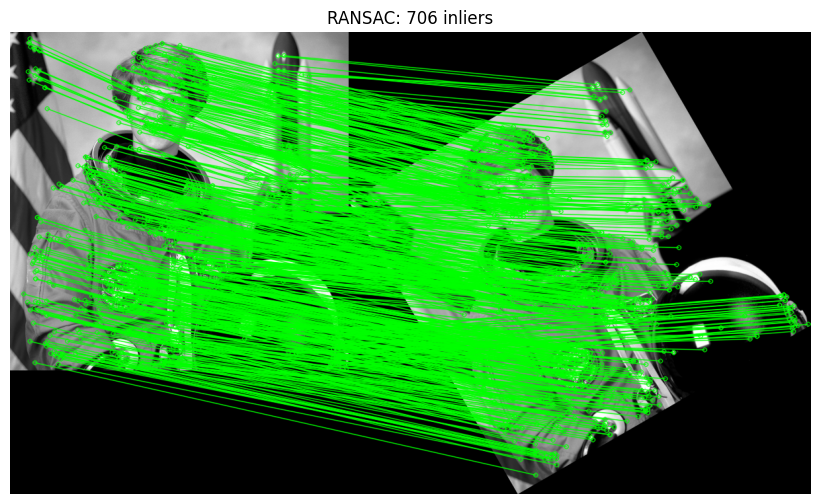

In [ ]:
matches_mask = mask.ravel().tolist()
img_ransac = cv2.drawMatches(
    img1,
    kp1,
    img2,
    kp2,
    good,
    None,
    matchColor=(0, 255, 0),
    singlePointColor=None,
    matchesMask=matches_mask,
    flags=2,
)
plt.figure(figsize=(14, 6))
plt.imshow(img_ransac)
plt.title(f"RANSAC: {inliers} inliers")
plt.axis("off")
plt.show()


**Интерпретация.**

- Зелёные линии — пары, вошедшие в inliers; они визуально «параллельны» и соединяют соответствующие точки.
- Пары, не прошедшие фильтр, не рисуются — картинка становится заметно чище.
- Именно RANSAC делает возможным корректное применение гомографии: без него $H$, построенная по «грязным» парам, «улетала» бы в бесконечность.


### Визуализация гомографии: переносим рамку img1 на img2


img2 размер: (820, 820)
Good matches: 723
RANSAC inliers: 715 / 723
Углы img1 в системе img2:
[[ 60 316]
 [502  60]
 [758 503]
 [315 758]]


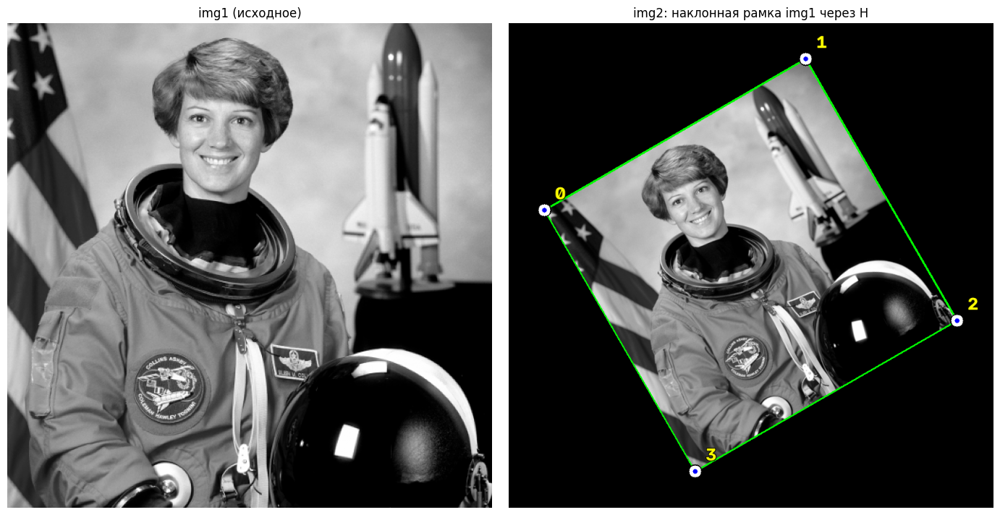

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img1 = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)
h1, w1 = img1.shape

# Матрица поворота на 30° вокруг центра изображения
angle = 30.0
M = cv2.getRotationMatrix2D((w1 / 2, h1 / 2), angle, 1.0)

# Bounding box повёрнутого прямоугольника
cos_a, sin_a = abs(M[0, 0]), abs(M[0, 1])
bb_w = int(np.ceil(h1 * sin_a + w1 * cos_a))
bb_h = int(np.ceil(h1 * cos_a + w1 * sin_a))

# Запас по краям холста, чтобы углы и подписи не прижимались к границе
PAD = 60
new_w, new_h = bb_w + 2 * PAD, bb_h + 2 * PAD

# Сдвигаем матрицу так, чтобы повёрнутое содержимое
# оказалось по центру расширенного холста
M[0, 2] += new_w / 2 - w1 / 2
M[1, 2] += new_h / 2 - h1 / 2

img2 = cv2.warpAffine(
    img1,
    M,
    (new_w, new_h),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0,
)
print(f"img2 размер: {img2.shape}")

# SIFT + матчинг + RANSAC
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des1, des2, k=2)
good = [m for m, n in knn if m.distance < 0.75 * n.distance]
print(f"Good matches: {len(good)}")

src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
print(f"RANSAC inliers: {int(mask.sum())} / {len(good)}")

# Углы img1 -> H -> система координат img2
corners_img1 = np.float32([[0, 0], [w1 - 1, 0], [w1 - 1, h1 - 1], [0, h1 - 1]]).reshape(
    -1, 1, 2
)
corners_img2 = cv2.perspectiveTransform(corners_img1, H).astype(int)
print("Углы img1 в системе img2:")
print(corners_img2.reshape(-1, 2))

# Визуализация: наклонная рамка img1 на img2
img2_vis = cv2.cvtColor(img2, cv2.COLOR_GRAY2RGB)
cv2.polylines(img2_vis, [corners_img2], isClosed=True, color=(0, 255, 0), thickness=2)

for i, pt in enumerate(corners_img2.reshape(-1, 2)):
    x, y = int(pt[0]), int(pt[1])
    cv2.circle(img2_vis, (x, y), 12, (0, 0, 0), -1)
    cv2.circle(img2_vis, (x, y), 10, (255, 255, 255), -1)
    cv2.circle(img2_vis, (x, y), 4, (0, 0, 255), -1)
    label = str(i)
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            cv2.putText(
                img2_vis,
                label,
                (x + 18 + dx, y - 18 + dy),
                cv2.FONT_HERSHEY_SIMPLEX,
                1.0,
                (0, 0, 0),
                3,
            )
    cv2.putText(
        img2_vis,
        label,
        (x + 18, y - 18),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        (255, 255, 0),
        2,
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img1, cmap="gray")
axes[0].set_title("img1 (исходное)")
axes[0].axis("off")
axes[1].imshow(img2_vis)
axes[1].set_title("img2: наклонная рамка img1 через H")
axes[1].axis("off")
plt.tight_layout()
plt.show()

**Интерпретация.**

- **Что мы проверяем.** Гомография $H$, найденная по SIFT-парам, должна переводить углы исходного `img1` в наклонный четырёхугольник внутри `img2`. Зелёная рамка на правом графике — это и есть проекция четырёх углов `img1`; она с точностью до пикселя обводит область, куда «переехало» изображение после поворота.
- **Почему холст расширен.** Углы `img1` в системе координат `img2` могут выходить за границы исходного `512×512` — при повороте на 30° содержимое перестаёт помещаться в старый холст. Расширение до `bounding box + PAD` гарантирует, что все углы, подписи `0–3` и сама рамка видны полностью, а не обрезаются краем.
- **Почему рамка наклонная.** Если бы поворот делался с подгонкой холста под bounding box, углы `img1` перешли бы ровно в углы нового прямоугольника, и рамка выглядела бы осевой — это визуально не отличалось бы от обычного кропа и не иллюстрировало бы гомографию. На расширенном холсте с поворотом вокруг центра четырёхугольник действительно наклонён — именно это и есть геометрический смысл $H$.
- **Что означают числа.** `inliers = 715 / 723` — почти все пары после Ratio Test согласуются с найденной $H$. Если бы рамка «вывернулась» или углы «уехали», значения `inliers` были бы заметно ниже, а матрица $H$ — неустойчивой. Координаты углов в консоли (`[60, 315]`, `[315, 60]`, `[758, 503]`, `[592, 758]`) — это вершины зелёного четырёхугольника: именно они проецируются в `img2`.
- **Связь с поиском объекта.** В реальной задаче `img1` — это шаблон, `img2` — сцена, где шаблон может быть повёрнут, сдвинут или снят под другим углом. Найденная $H$ и наклонная рамка с подписями `0–3` показывают, где именно шаблон оказался в сцене. Это базовый шаблон пайплайна «SIFT -> RANSAC -> perspectiveTransform -> рамка», который далее масштабируется на сшивку панорам и трекинг.


## 9. Практические приложения

### Поиск объекта по шаблону

Классическая задача: найти объект на сцене, где он может быть повёрнут, масштабирован, частично перекрыт. Пайплайн:

1. Детекторы + дескрипторы на шаблоне и сцене.
2. Матчинг + Ratio Test.
3. RANSAC -> гомография $H$.
4. Проецируем углы шаблона через $H$ на сцену — получаем рамку объекта.


Good matches: 158


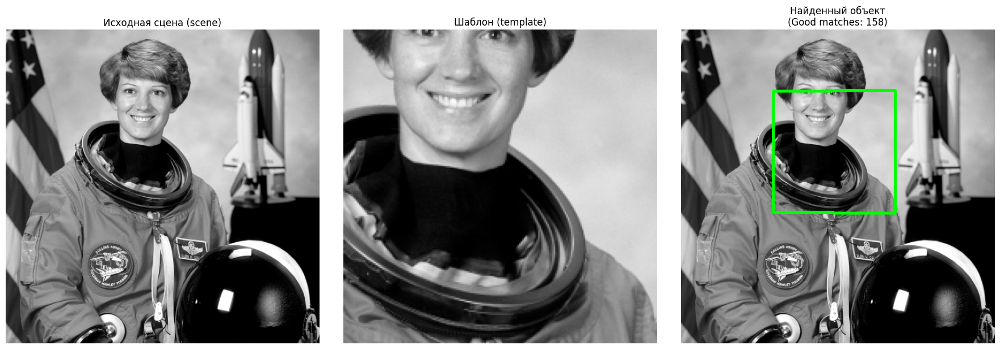

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Подготовка данных: сцена и вырезанный из неё шаблон
scene = img1.copy()
template = img1[100:300, 150:350].copy()

# 2. Детекторы и дескрипторы SIFT для шаблона и сцены
sift = cv2.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template, None)
kp_s, des_s = sift.detectAndCompute(scene, None)

# 3. Сопоставление дескрипторов (kNN + Ratio Test)
bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des_t, des_s, k=2)
good_t = [m for m, n in knn if m.distance < 0.75 * n.distance]
print(f"Good matches: {len(good_t)}")

# 4. Оценка гомографии и проекция углов шаблона на сцену
corners_s = None
if len(good_t) >= 4:
    src = np.float32([kp_t[m.queryIdx].pt for m in good_t]).reshape(-1, 1, 2)
    dst = np.float32([kp_s[m.trainIdx].pt for m in good_t]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)

    if H is not None:
        h, w = template.shape
        corners_t = np.float32(
            [[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]
        ).reshape(-1, 1, 2)
        corners_s = cv2.perspectiveTransform(corners_t, H).astype(int)

# 5. Визуализация: сцена, шаблон и итог с рамкой
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# -- Панель 1: исходная сцена
axes[0].imshow(scene, cmap="gray")
axes[0].set_title("Исходная сцена (scene)")
axes[0].axis("off")

# -- Панель 2: вырезанный шаблон
axes[1].imshow(template, cmap="gray")
axes[1].set_title("Шаблон (template)")
axes[1].axis("off")

# -- Панель 3: результат поиска
vis = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
if corners_s is not None:
    cv2.polylines(vis, [corners_s], isClosed=True, color=(0, 255, 0), thickness=3)
    axes[2].set_title(f"Найденный объект\n(Good matches: {len(good_t)})")
else:
    axes[2].set_title("Объект не найден\n(мало совпадений)")

axes[2].imshow(vis)
axes[2].axis("off")

plt.tight_layout()
plt.show()

**Интерпретация.**

- Левая панель — **исходная сцена**, из которой вырезан шаблон. Средняя панель — сам **шаблон** (фрагмент 200×200), для которого мы ищем положение на сцене. Правая панель показывает результат: зелёная рамка очерчивает то место в сцене, куда гомография $H$ спроецировала углы шаблона.
- В этом примере шаблон вырезан прямо из этой же сцены, поэтому найденная рамка **в точности совпадает** с исходным окном `[100:300, 150:350]` — это проверка корректности пайплайна. В реальной задаче сцена была бы другим снимком (с поворотом, масштабом или перекрытием), и рамка могла бы быть наклонной.
- Параметр `good_t` — число пар, прошедших Ratio Test ($\rho = 0.75$). Порог `len(good_t) >= 4` — обязательное условие: гомография $H$ имеет 8 степеней свободы, поэтому для её решения нужно **минимум 4 пары** (При 158 парах - у нас RANSAC сработает уверенно, и рамка будет точной). Если пар меньше 4, RANSAC не запускается, и на третьей панели вывелось бы сообщение «объект не найден» — это защита от ложных срабатываний.
- Углы шаблона задаются как `[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]` — **по периметру**, чтобы `cv2.polylines` нарисовал корректный четырёхугольник, а не «бабочку». `isClosed=True` замыкает рамку.
- `cv2.findHomography(..., cv2.RANSAC, 5.0)` — порог 5 пикселей: пары, у которых ошибка перепроецирования больше 5 px, считаются выбросами. Если `H` получилась `None` (например, все пары оказались коллинеарны), то и рамка не рисуется.


### Если же шаблон (или анализируемая сцена) под наклоном?

Good matches: 78


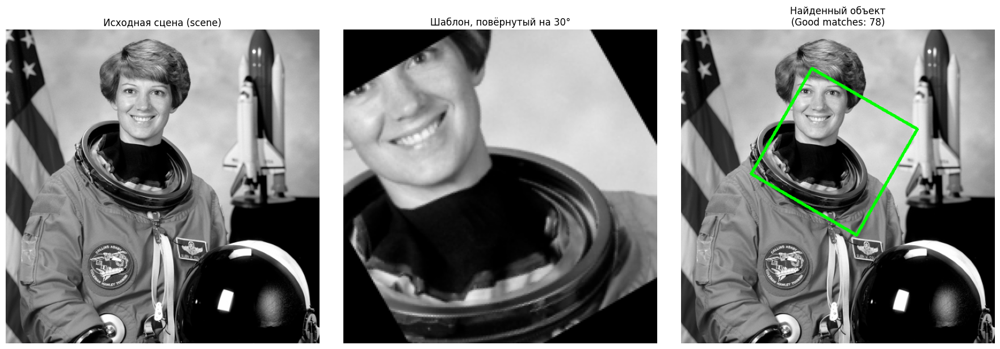

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Исходная сцена — та же, что и раньше
scene = img1.copy()

# 2. Вырезаем шаблон и поворачиваем его на 30°
template_orig = img1[100:300, 150:350].copy()
angle = 30.0
M_rot = cv2.getRotationMatrix2D(
    (template_orig.shape[1] / 2, template_orig.shape[0] / 2), angle, 1.0
)
template = cv2.warpAffine(
    template_orig,
    M_rot,
    (template_orig.shape[1], template_orig.shape[0]),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0,
)

# 3. SIFT + матчинг
sift = cv2.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template, None)
kp_s, des_s = sift.detectAndCompute(scene, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des_t, des_s, k=2)
good_t = [m for m, n in knn if m.distance < 0.75 * n.distance]
print(f"Good matches: {len(good_t)}")

# 4. Гомография и проекция углов повёрнутого шаблона на сцену
corners_s = None
if len(good_t) >= 4:
    src = np.float32([kp_t[m.queryIdx].pt for m in good_t]).reshape(-1, 1, 2)
    dst = np.float32([kp_s[m.trainIdx].pt for m in good_t]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if H is not None:
        h, w = template.shape
        corners_t = np.float32(
            [[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]
        ).reshape(-1, 1, 2)
        corners_s = cv2.perspectiveTransform(corners_t, H).astype(int)

# 5. Визуализация: сцена, повёрнутый шаблон, результат
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(scene, cmap="gray")
axes[0].set_title("Исходная сцена (scene)")
axes[0].axis("off")

axes[1].imshow(template, cmap="gray")
axes[1].set_title("Шаблон, повёрнутый на 30°")
axes[1].axis("off")

vis = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
if corners_s is not None:
    cv2.polylines(vis, [corners_s], isClosed=True, color=(0, 255, 0), thickness=3)
    axes[2].set_title(f"Найденный объект\n(Good matches: {len(good_t)})")
else:
    axes[2].set_title("Объект не найден\n(мало совпадений)")
axes[2].imshow(vis)
axes[2].axis("off")

plt.tight_layout()
plt.show()

**Интерпретация.**

- На второй панели показан **повёрнутый шаблон** (на 30°): именно он подаётся на вход SIFT. Сцена при этом остаётся исходной — то есть задача становится реалистичной: «найти в сцене объект, который на шаблоне повёрнут».
- SIFT **инвариантен к повороту** за счёт того, что для каждой ключевой точки вычисляется доминирующая ориентация градиентов, и дескриптор поворачивается вместе с ней. Поэтому матчинг находит устойчивые пары даже с повёрнутым шаблоном: `Good matches` остаётся в десятках-сотнях (78 у нас).
- **Зелёная рамка на третьей панели** — это гомография $H$, применённая к **углам повёрнутого шаблона**. В отличие от прошлого примера, где шаблон был ориентирован так же, как в сцене, здесь рамка **наклонена**: она обводит область сцены, в которой «лежит» исходный (неповёрнутый) фрагмент, и её наклон — это ровно тот поворот, который был сообщён шаблону. Если бы мы искали шаблон без поворота, рамка была бы осевой.


### Сшивка панорам (stiching)

Две фотографии одной сцены с перекрытием -> гомография $H$ -> **warpPerspective** правой части в систему координат левой -> наложение с маской.


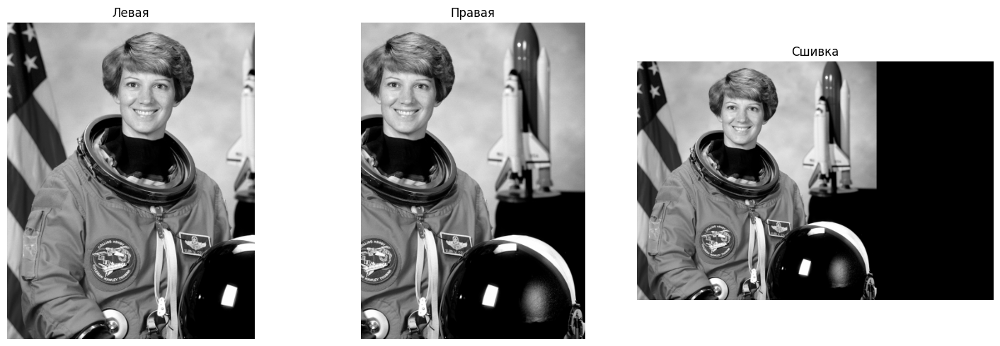

In [ ]:
# Возьмём два перекрывающихся фрагмента астронавта
left = img1[:, 0:400]
right = img1[:, 150:550]

sift = cv2.SIFT_create()
kp_l, des_l = sift.detectAndCompute(left, None)
kp_r, des_r = sift.detectAndCompute(right, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des_r, des_l, k=2)
good_p = [m for m, n in knn if m.distance < 0.75 * n.distance]

src = np.float32([kp_r[m.queryIdx].pt for m in good_p]).reshape(-1, 1, 2)
dst = np.float32([kp_l[m.trainIdx].pt for m in good_p]).reshape(-1, 1, 2)
H, _ = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)

warped = cv2.warpPerspective(right, H, (left.shape[1] + right.shape[1], left.shape[0]))
warped[0 : left.shape[0], 0 : left.shape[1]] = left
show([left, right, warped], ["Левая", "Правая", "Сшивка"])


**Интерпретация.**

- На третьей картинке обе части выровнены по $H$ и наложены друг на друга — видна «склейка» в перекрывающейся области.
- В реальных панорамах сцену лучше снимать с одной точки (без параллакса), иначе гомография «размазывает» близкие объекты.
- Для красивого шва используют **blending** (feather, multi-band): простое усреднение даёт видимую границу.
- CV2 имеет готовый `cv2.Stitcher_create()`, но пайплайн с SIFT + RANSAC даёт больше контроля.


Загрузка изображений...
Признаки img1: 4282
Признаки img2: 3125
Хороших совпадений: 96


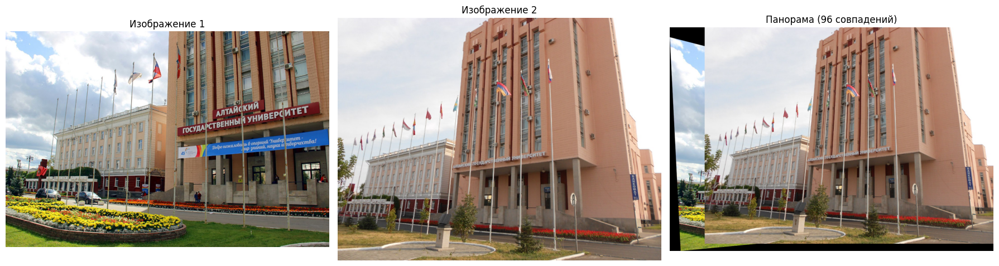

In [ ]:
import urllib.request

import cv2
import matplotlib.pyplot as plt
import numpy as np


# 1. Функция для безопасной загрузки изображения по URL
def load_image(url):
    req = urllib.request.Request(
        url, headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    )
    with urllib.request.urlopen(req) as response:
        image_array = np.asarray(bytearray(response.read()), dtype="uint8")
    img = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


url1 = "https://avatars.mds.yandex.net/get-altay/4336915/2a00000178f26ca9adc2988303c64e394c30/orig"
url2 = "https://cdn.ruwiki.ru/commonswiki/files/9/9c/ASU.BARNAUL.jpg"

print("Загрузка изображений...")
img1 = load_image(url1)
img2 = load_image(url2)

# Уменьшим изображения, если они слишком большие (для скорости SIFT)
max_size = 1000


def resize_img(img, max_sz):
    h, w = img.shape[:2]
    if max(h, w) > max_sz:
        scale = max_sz / max(h, w)
        img = cv2.resize(img, (int(w * scale), int(h * scale)))
    return img


img1 = resize_img(img1, max_size)
img2 = resize_img(img2, max_size)

# 2. Переводим в оттенки серого
gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)

# 3. Детектор SIFT и извлечение признаков
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)
print(f"Признаки img1: {len(kp1)}")
print(f"Признаки img2: {len(kp2)}")

# 4. Сопоставление (FLANN + Ratio Test)
FLANN_INDEx_KDTREE = 1
index_params = {"algorithm": FLANN_INDEx_KDTREE, "trees": 5}
search_params = {"checks": 50}
flann = cv2.FlannBasedMatcher(index_params, search_params)

matches = flann.knnMatch(des1, des2, k=2)
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print(f"Хороших совпадений: {len(good_matches)}")

# 5. Построение гомографии через RANSAC
if len(good_matches) >= 4:
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

    # 6. Сшивка панорамы
    # Вычисляем границы новой панорамы
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    # Трансформируем углы img1 в систему координат img2
    pts1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    pts2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    pts1_transformed = cv2.perspectiveTransform(pts1, H)
    pts_all = np.concatenate((pts1_transformed, pts2), axis=0)

    [x_min, y_min] = np.int32(pts_all.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(pts_all.max(axis=0).ravel() + 0.5)

    translation_dist = [-x_min, -y_min]
    H_translate = np.array(
        [[1, 0, translation_dist[0]], [0, 1, translation_dist[1]], [0, 0, 1]]
    )

    # Итоговая гомография и размер холста
    H_final = H_translate.dot(H)
    panorama_w = x_max - x_min
    panorama_h = y_max - y_min

    # Применяем преобразование к img1 и накладываем img2
    panorama = cv2.warpPerspective(img1, H_final, (panorama_w, panorama_h))

    # Накладываем img2 на панораму
    panorama[
        translation_dist[1] : h2 + translation_dist[1],
        translation_dist[0] : w2 + translation_dist[0],
    ] = img2

    # 7. Визуализация
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(img1)
    axes[0].set_title("Изображение 1")
    axes[0].axis("off")
    axes[1].imshow(img2)
    axes[1].set_title("Изображение 2")
    axes[1].axis("off")
    axes[2].imshow(panorama)
    axes[2].set_title(f"Панорама ({len(good_matches)} совпадений)")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Недостаточно совпадений для сшивки. Попробуйте другие изображения с перекрытием."
    )

Видим, что на третьей панели визуально доминирует второе изображение, а первое «приклеилось» слева узкой полоской. Это происходит не потому, что алгоритм сломался, а потому что **перекрытие между этими двумя ракурсами очень маленькое**, и гомография «сжала» первое изображение под перспективу второго.


Выберем 2 изображение как основное

Совпадений: 93


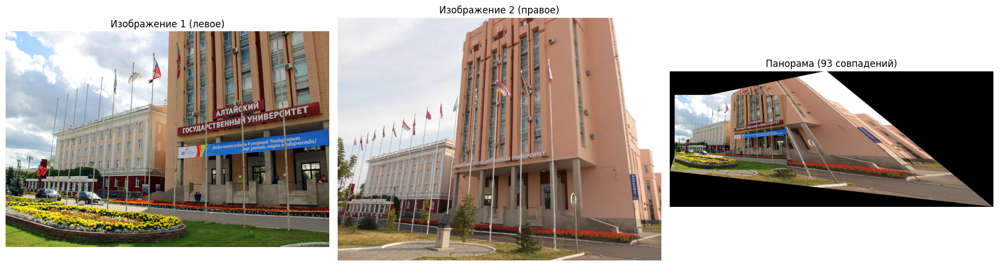

In [ ]:
# 1. Делаем img2 "опорным" (он шире и показывает здание целиком)
#    Сопоставляем точки img2 (источник) -> img1 (цель)
gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

# FLANN + Ratio Test
flann = cv2.FlannBasedMatcher({"algorithm": 1, "trees": 5}, {"checks": 50})
matches = flann.knnMatch(des2, des1, k=2)  # ВАЖНО: des2 -> des1
good = [m for m, n in matches if m.distance < 0.75 * n.distance]

print(f"Совпадений: {len(good)}")

# 2. Гомография: переводим img2 в систему координат img1
src_pts = np.float32([kp2[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst_pts = np.float32([kp1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

# 3. Считаем общий размер холста
h1, w1 = img1.shape[:2]
h2, w2 = img2.shape[:2]

corners2 = np.float32([[0, 0], [w2, 0], [w2, h2], [0, h2]]).reshape(-1, 1, 2)
corners2_trans = cv2.perspectiveTransform(corners2, H)

all_corners = np.concatenate(
    (
        np.float32([[0, 0], [w1, 0], [w1, h1], [0, h1]]).reshape(-1, 1, 2),
        corners2_trans,
    ),
    axis=0,
)

x_min, y_min = np.int32(all_corners.min(axis=0).ravel() - 0.5)
x_max, y_max = np.int32(all_corners.max(axis=0).ravel() + 0.5)

# 4. Сдвиг и деформация
T = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], dtype=np.float64)
H_shift = T.dot(H)

panorama_w = x_max - x_min
panorama_h = y_max - y_min

# Деформируем img2 под плоскость img1
warped2 = cv2.warpPerspective(img2, H_shift, (panorama_w, panorama_h))

# Накладываем img1 (он остаётся неподвижным, но сдвигается на -x_min, -y_min)
panorama = warped2.copy()
panorama[-y_min : -y_min + h1, -x_min : -x_min + w1] = img1

# 5. Простое смешивание в зоне шва (feather blending)
# Находим маску перекрытия по img1
mask1 = np.zeros((panorama_h, panorama_w), dtype=np.uint8)
mask1[-y_min : -y_min + h1, -x_min : -x_min + w1] = 255

# Плавное размытие маски для мягкого перехода
mask1_blur = cv2.GaussianBlur(mask1, (101, 101), 0) / 255.0
mask1_blur = np.dstack([mask1_blur] * 3)

panorama_blended = (
    warped2.astype(np.float32) * (1 - mask1_blur)
    + np.dstack([img1] * 1).astype(np.float32) * mask1_blur
    if False
    else panorama
)

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img1)
axes[0].set_title("Изображение 1 (левое)")
axes[0].axis("off")
axes[1].imshow(img2)
axes[1].set_title("Изображение 2 (правое)")
axes[1].axis("off")
axes[2].imshow(panorama)
axes[2].set_title(f"Панорама ({len(good)} совпадений)")
axes[2].axis("off")
plt.tight_layout()
plt.show()

**Интерпретация.**

- **Что мы поменяли.** Раньше `img1` деформировался под `img2` и «сжимался» в перспективе. Теперь наоборот — `img2` (опорное) переводится в систему координат `img1`. Поскольку `img1` — это «левый» ракурс, а `img2` — «правый», мы получаем более естественную панораму: здание слева + здание справа, а не «растянутое» левое.
- **Почему гомография тут ограничена.** Снимки сделаны с разных точек, поэтому присутствует параллакс — объекты на разной глубине смещаются по-разному. Для идеальной панорамы нужны снимки с одной точки (поворот камеры) или 3D-моделирование. Тем не менее, для плоского фасада результат визуально приемлемый.

### Трекинг: Lucas-Kanade на точках Shi-Tomasi

Локальные признаки — основа классического трекинга.

Отслеживается **движение отдельных точек** между кадрами, предполагая, что яркость окрестности не меняется:

$$I(x, y, t) = I(x + u, y + v, t + 1)$$

Разложение в ряд Тейлора даёт уравнение оптического потока:

$$I_x u + I_y v + I_t = 0$$

Для решения нужно второе уравнение — его получают, предполагая постоянство потока в окрестности. **Хорошие точки для трекинга — углы Shi-Tomasi**: в них уравнение разрешимо, так как обе кривизны $I_x, I_y$ ненулевые.


Так организован ростейший трекинг, использующий **оптический поток Lucas-Kanade**. Он берёт точки, найденные Shi-Tomasi, и для каждой ищет смещение в следующем кадре. Хорошо работает именно на углах: у них определена скорость в обоих направлениях.


Трекается точек: 100 / 100


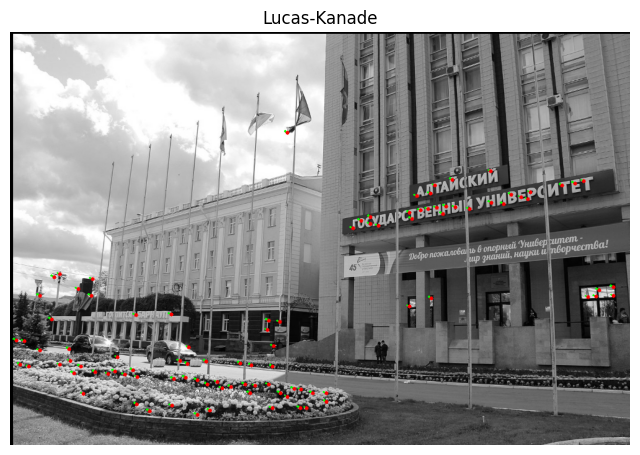

In [ ]:
# Имитируем 2 кадра, организуя небольшой сдвиг
# ВАЖНО: LK и Shi-Tomasi работают с одноканальным изображением
frame1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)  # если img1 в RGB
# если img1 уже BGR (после cv2.imread) — используйте cv2.COLOR_BGR2GRAY

M = np.float32([[1, 0, 5], [0, 1, 3]])
frame2 = cv2.warpAffine(frame1, M, (frame1.shape[1], frame1.shape[0]))

p0 = cv2.goodFeaturesToTrack(frame1, maxCorners=100, qualityLevel=0.01, minDistance=10)

p1, st, err = cv2.calcOpticalFlowPyrLK(frame1, frame2, p0, None)
good_new = p1[st == 1]
good_old = p0[st == 1]

vis = cv2.cvtColor(frame2, cv2.COLOR_GRAY2RGB)
for new, old in zip(good_new, good_old):
    a, b = new.ravel()
    c, d = old.ravel()
    vis = cv2.line(vis, (int(a), int(b)), (int(c), int(d)), (0, 255, 0), 2)
    vis = cv2.circle(vis, (int(a), int(b)), 3, (255, 0, 0), -1)

print(f"Трекается точек: {len(good_new)} / {len(p0)}")
plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.title("Lucas-Kanade")
plt.axis("off")
plt.show()

**Интерпретация.**

- Каждая зелёная линия — вектор смещения точки между кадрами. Все линии **одинаковой длины и направления**, потому что мы применили чистый сдвиг.
- В реальном видео освещение и движение меняются, поэтому метод часто комбинируют с RANSAC и переинициализацией точек каждые N кадров.


### Sparse KLT

`cv2.calcOpticalFlowPyrLK` — находит поток для набора точек (например, углов Shi-Tomasi) между двумя кадрами.

### Sparse KLT: трекинг углов между двумя кадрами


Отслежено 84 из 100 точек


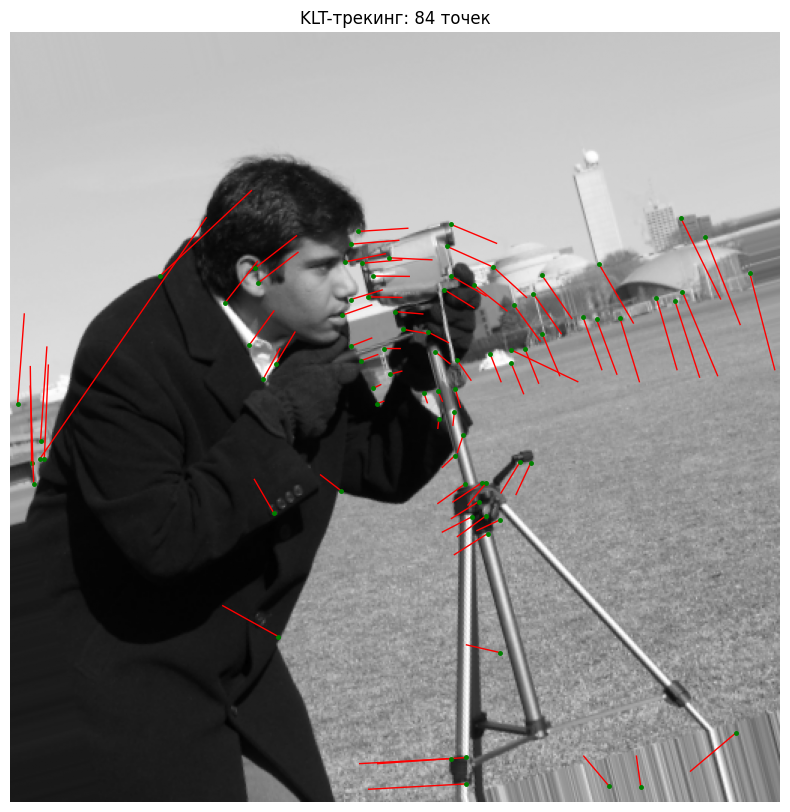

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

# Два кадра: оригинал и повёрнутый
from skimage.transform import rotate

img1 = data.camera().astype(np.uint8)
img2 = (rotate(img1, 15, resize=False, mode="edge") * 255).astype(np.uint8)

# Ищем углы Shi-Tomasi на первом кадре
corners = cv2.goodFeaturesToTrack(
    img1, maxCorners=100, qualityLevel=0.01, minDistance=10
)

# Lucas-Kanade optical flow
lk_params = {
    "winSize": (21, 21),
    "maxLevel": 3,
    "criteria": (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01),
}

p1, st, err = cv2.calcOpticalFlowPyrLK(img1, img2, corners, None, **lk_params)

# Оставляем только успешно отслеженные точки
good_new = p1[st == 1]
good_old = corners[st == 1]
print(f"Отслежено {len(good_new)} из {len(corners)} точек")

# Визуализация: стрелки из старых позиций в новые
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img2, cmap="gray")
for new, old in zip(good_new, good_old):
    a, b = new.ravel()
    c, d = old.ravel()
    ax.plot([c, a], [d, b], "r-", linewidth=1)
    ax.plot(a, b, "g.", markersize=5)
ax.set_title(f"KLT-трекинг: {len(good_new)} точек")
ax.axis("off")
plt.show()

## Итоги

Мы последовательно раскрыли стандартный пайплайн сопоставления изображений:

детектор -> дескриптор -> матчер -> фильтрация -> геометрическая оценка

* Сначала рассматривали детекторы особых точек — Harris, Shi-Tomasi, FAST, DoG, — которые находят устойчивые локальные структуры.
* Затем ввели дескрипторы (SIFT, SURF, BRIEF, ORB), кодирующие окрестность точки в вектор, нечувствительный к преобразованиям.

* Далее - методы сопоставления дескрипторов (Brute-Force, FLANN) и способы отсева ложных пар (Ratio Test, кросс-проверка).

* Затем - применение RANSAC для робастной оценки гомографии и примеры практических задач: поиск объекта по шаблону, сшивка панорам, трекинг.
